In [1]:
import kairo
import pandas as pd

import warnings
warnings.filterwarnings("ignore")

from dotenv import load_dotenv
from pathlib import Path
import os

load_dotenv(Path("../..") / ".env")

True

In [2]:
log = kairo.read_log("../../data/thesis/general/running_example/L3.xes",
    case_id = "case:concept:name",
    activity = "concept:name",
    timestamp = "time:timestamp",
    event_id = "event:id",
    start_timestamp = "start_timestamp",
    resource = "org:resource",
    event_duration = "event:duration_min")
log.head()

,event_id,start_timestamp,time:timestamp,case:concept:name,concept:name,event_duration,case:region,org:resource,case:amount
0,evt_00000001,2020-01-01 00:00:00+00:00,2020-01-01 00:17:34+00:00,case_000001,a,17.566667,region_4,res_01,780.51
1,evt_00000002,2020-01-01 00:21:20+00:00,2020-01-01 00:49:19+00:00,case_000001,b,27.983333,region_4,res_01,780.51
2,evt_00000003,2020-01-01 01:00:53+00:00,2020-01-01 01:40:48+00:00,case_000001,c,39.916667,region_4,res_02,780.51
3,evt_00000004,2020-01-01 01:57:16+00:00,2020-01-01 02:16:29+00:00,case_000001,d,19.216667,region_4,res_01,780.51
4,evt_00000005,2020-01-01 02:31:23+00:00,2020-01-01 02:57:12+00:00,case_000001,e,25.816667,region_4,res_04,780.51


In [3]:
stats = kairo.compute_log_stats(log)
stats

{'cases': 4920,
 'events': 24600,
 'activities': 5,
 'resources': 4,
 'start': Timestamp('2020-01-01 00:17:34+0000', tz='UTC'),
 'end': Timestamp('2020-12-31 02:02:27+0000', tz='UTC'),
 'span_minutes': 525704.8833333333,
 'tpt_days_min': 0.0634837962962963,
 'tpt_days_mean': 0.12618319265657935,
 'tpt_days_median': 0.12561921296296297,
 'tpt_days_max': 0.20038194444444443,
 'length_min': 5,
 'length_mean': 5.0,
 'length_median': 5.0,
 'length_max': 5,
 'activity_counts': concept:name
 a    4920
 b    4920
 c    4920
 d    4920
 e    4920
 Name: count, dtype: int64,
 'resource_counts': org:resource
 res_02    9065
 res_01    7166
 res_03    5161
 res_04    3208
 Name: count, dtype: int64}

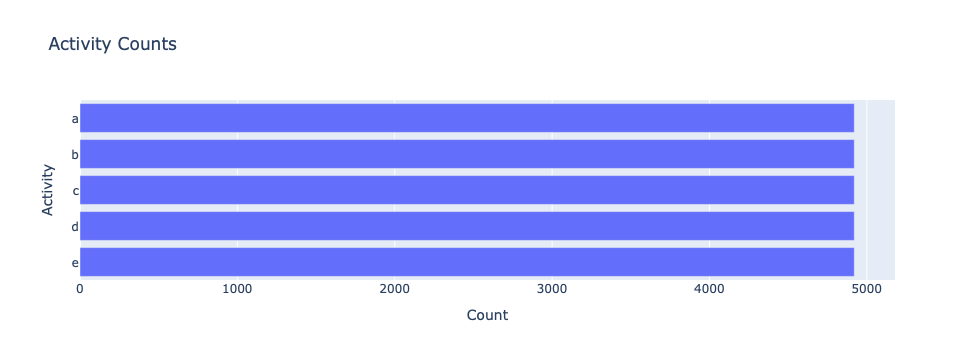

In [4]:
activity_plot = kairo.plot_activity_counts(stats)
activity_plot.show()

In [5]:
features = kairo.compute_features_intra(log, sliding_window_size=6)
features

,case:concept:name,time:timestamp,act_freqs:a,act_freqs:b,act_freqs:c,act_freqs:d,act_freqs:e,df_counts:a -> b,df_counts:a -> c,df_counts:b -> c,...,past_acts_5:a,past_acts_5:b,past_acts_5:c,past_acts_5:d,past_acts_5:e,past_acts_6:a,past_acts_6:b,past_acts_6:c,past_acts_6:d,past_acts_6:e
0,case_000001,2020-01-01 00:17:34+00:00,1.000000,0.000000,0.000000,0.00,0.00,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,case_000001,2020-01-01 00:49:19+00:00,0.500000,0.500000,0.000000,0.00,0.00,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,case_000001,2020-01-01 01:40:48+00:00,0.333333,0.333333,0.333333,0.00,0.00,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,case_000001,2020-01-01 02:16:29+00:00,0.250000,0.250000,0.250000,0.25,0.00,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,case_000001,2020-01-01 02:57:12+00:00,0.200000,0.200000,0.200000,0.20,0.20,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24595,case_004920,2020-12-30 22:43:37+00:00,1.000000,0.000000,0.000000,0.00,0.00,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
24596,case_004920,2020-12-30 23:34:17+00:00,0.500000,0.500000,0.000000,0.00,0.00,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
24597,case_004920,2020-12-31 00:35:15+00:00,0.333333,0.333333,0.333333,0.00,0.00,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
24598,case_004920,2020-12-31 01:06:16+00:00,0.250000,0.250000,0.250000,0.00,0.25,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [6]:
std_features = kairo.standardize(features, method="minmax")
std_features

,case:concept:name,time:timestamp,act_freqs:a,act_freqs:b,act_freqs:c,act_freqs:d,act_freqs:e,df_counts:a -> b,df_counts:a -> c,df_counts:b -> c,...,past_acts_5:a,past_acts_5:b,past_acts_5:c,past_acts_5:d,past_acts_5:e,past_acts_6:a,past_acts_6:b,past_acts_6:c,past_acts_6:d,past_acts_6:e
0,case_000001,2020-01-01 00:17:34+00:00,1.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,case_000001,2020-01-01 00:49:19+00:00,0.375000,1.000000,0.000000,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,case_000001,2020-01-01 01:40:48+00:00,0.166667,0.666667,0.666667,0.0,0.0,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,case_000001,2020-01-01 02:16:29+00:00,0.062500,0.500000,0.500000,1.0,0.0,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,case_000001,2020-01-01 02:57:12+00:00,0.000000,0.400000,0.400000,0.8,0.8,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24595,case_004920,2020-12-30 22:43:37+00:00,1.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
24596,case_004920,2020-12-30 23:34:17+00:00,0.375000,1.000000,0.000000,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
24597,case_004920,2020-12-31 00:35:15+00:00,0.166667,0.666667,0.666667,0.0,0.0,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
24598,case_004920,2020-12-31 01:06:16+00:00,0.062500,0.500000,0.500000,0.0,1.0,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


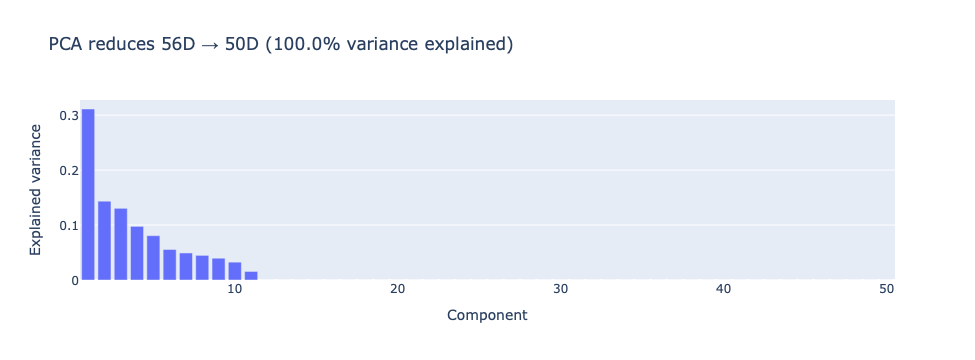

In [7]:
pca = kairo.compute_pca(std_features, num_components=50)
pca_plot = kairo.plot_pca_variances(pca)
pca_plot.show()
#pca

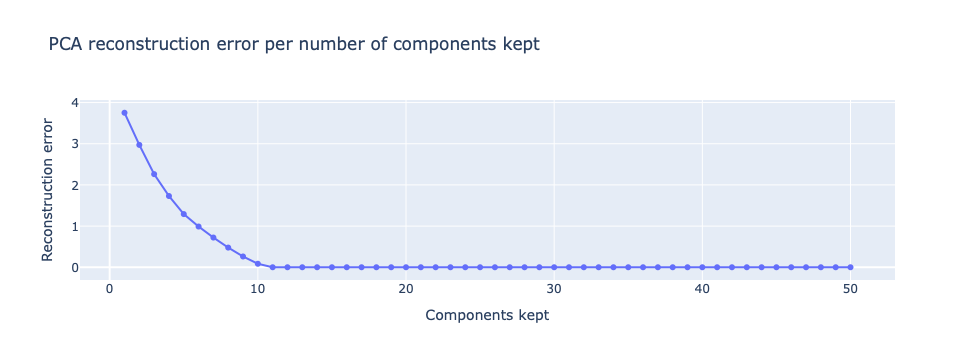

In [8]:
reconstruction_errors = kairo.compute_pca_reconstruction_errors(std_features, pca)
reconstruction_plot = kairo.plot_pca_reconstruction_errors(reconstruction_errors)
reconstruction_plot.show()

In [9]:
compressed_features = kairo.apply_pca(std_features, pca, cut_component=18)
compressed_features

,case:concept:name,time:timestamp,pc_1,pc_2,pc_3,pc_4,pc_5,pc_6,pc_7,pc_8,pc_9,pc_10,pc_11,pc_12,pc_13,pc_14,pc_15,pc_16,pc_17,pc_18
0,case_000001,2020-01-01 00:17:34+00:00,-1.614168,-0.881133,-0.632169,0.289071,-0.406508,-0.087372,0.164258,0.069191,-0.220649,0.006666,0.001461,1.010303e-14,1.226796e-14,2.176037e-14,-6.328271e-15,4.593548e-15,-8.326673e-17,1.387779e-17
1,case_000001,2020-01-01 00:49:19+00:00,-0.983522,0.479395,-0.397352,-0.161309,1.467027,0.232200,-0.023310,0.159890,0.269993,0.229985,0.012523,3.530509e-14,2.087219e-14,-5.551115e-17,-2.275957e-15,-3.608225e-16,3.859760e-16,1.804112e-16
2,case_000001,2020-01-01 01:40:48+00:00,-0.213215,1.543043,0.130722,-0.719502,-0.754615,0.246791,0.107068,0.029003,-0.322300,0.389050,0.024703,-1.665335e-14,-5.551115e-15,1.626477e-14,6.050715e-15,-4.864165e-15,-1.387779e-16,9.714451e-17
3,case_000001,2020-01-01 02:16:29+00:00,1.159225,0.916947,-0.271299,1.824610,-0.136443,-0.304827,-0.344667,-0.034373,0.090890,0.039277,0.202535,-1.243450e-14,-1.110223e-14,-2.919887e-14,-1.593170e-14,-3.343159e-14,2.359224e-16,-1.665335e-16
4,case_000001,2020-01-01 02:57:12+00:00,2.205051,-0.397108,-1.342073,-0.927529,0.016967,-0.402841,-0.433842,0.202164,-0.075805,-0.277344,0.199728,-2.264855e-14,-1.670886e-14,-3.608225e-14,2.886580e-15,1.984524e-15,-1.665335e-16,2.359224e-16
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24595,case_004920,2020-12-30 22:43:37+00:00,-1.614168,-0.881133,-0.632169,0.289071,-0.406508,-0.087372,0.164258,0.069191,-0.220649,0.006666,0.001461,1.010303e-14,1.226796e-14,2.176037e-14,-6.328271e-15,4.593548e-15,-8.326673e-17,1.387779e-17
24596,case_004920,2020-12-30 23:34:17+00:00,-0.983522,0.479395,-0.397352,-0.161309,1.467027,0.232200,-0.023310,0.159890,0.269993,0.229985,0.012523,3.530509e-14,2.087219e-14,-5.551115e-17,-2.275957e-15,-3.608225e-16,3.859760e-16,1.804112e-16
24597,case_004920,2020-12-31 00:35:15+00:00,-0.213215,1.543043,0.130722,-0.719502,-0.754615,0.246791,0.107068,0.029003,-0.322300,0.389050,0.024703,-1.665335e-14,-5.551115e-15,1.626477e-14,6.050715e-15,-4.864165e-15,-1.387779e-16,9.714451e-17
24598,case_004920,2020-12-31 01:06:16+00:00,1.003921,0.542489,-0.224651,0.331163,0.035917,-0.923205,1.452081,-1.090500,0.603092,-0.012400,-0.560533,-2.042810e-14,6.661338e-16,1.521006e-14,2.203793e-14,4.450607e-14,-1.804112e-16,-3.053113e-16


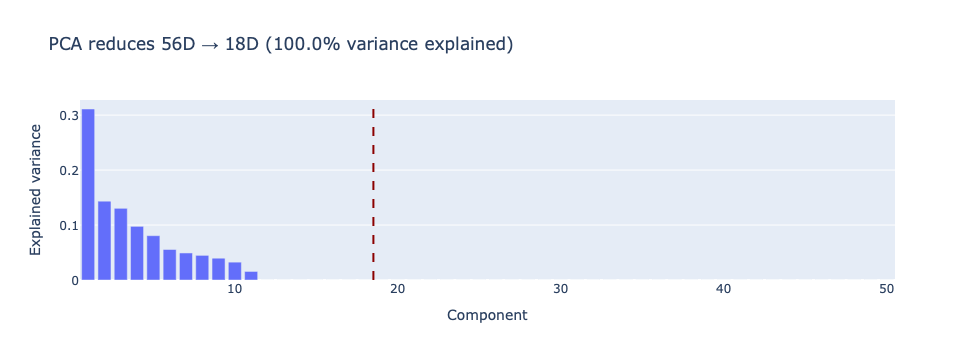

In [10]:
pca_plot_cut = kairo.plot_pca_variances(pca, cut_component=18)
pca_plot_cut.show()

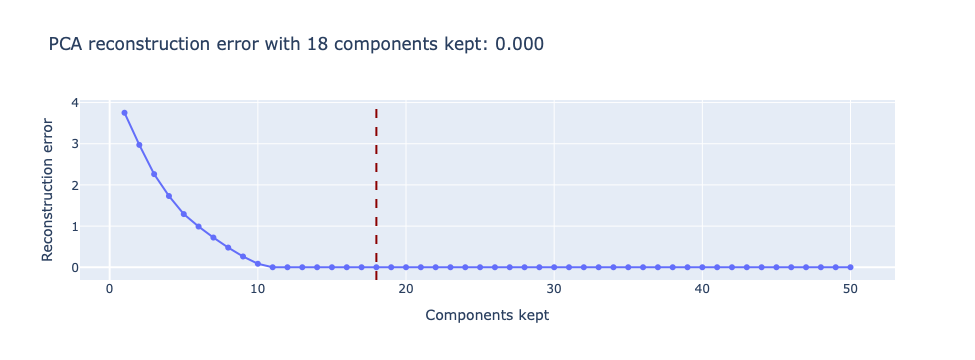

In [11]:
reconstruction_plot_cut = kairo.plot_pca_reconstruction_errors(reconstruction_errors, cut_component=18)
reconstruction_plot_cut.show()

In [12]:
som = kairo.compute_som(compressed_features, size=(10,10))
clusters = kairo.get_som_states(compressed_features, som)
clusters

,i,j
0,0,5
1,5,0
2,6,4
3,0,9
4,9,0
...,...,...
24595,0,5
24596,5,0
24597,6,4
24598,3,6


In [13]:
clustering_scores = [
    {"type": "Quantization error", "value": kairo.compute_som_quantization_error(compressed_features, clusters, som)},
    {"type": "Occupancy entropy", "value": kairo.compute_som_occupancy_entropy(clusters, size=som.get_weights().shape[:2])},
    {"type": "Silhouette", "value": kairo.compute_silhouette(compressed_features, clusters)},
    {"type": "Calinski-Harabasz", "value": kairo.compute_calinski_harabasz(compressed_features, clusters)},
]
clustering_scores

[{'type': 'Quantization error', 'value': 6.844992862356828e-16},
 {'type': 'Occupancy entropy', 'value': 0.519507330304893},
 {'type': 'Silhouette', 'value': 0.9999999983942051},
 {'type': 'Calinski-Harabasz', 'value': 1.109702520397529e+30}]

In [14]:
features_and_clusters = pd.concat([compressed_features, clusters], axis=1)
features_and_clusters

,case:concept:name,time:timestamp,pc_1,pc_2,pc_3,pc_4,pc_5,pc_6,pc_7,pc_8,...,pc_11,pc_12,pc_13,pc_14,pc_15,pc_16,pc_17,pc_18,i,j
0,case_000001,2020-01-01 00:17:34+00:00,-1.614168,-0.881133,-0.632169,0.289071,-0.406508,-0.087372,0.164258,0.069191,...,0.001461,1.010303e-14,1.226796e-14,2.176037e-14,-6.328271e-15,4.593548e-15,-8.326673e-17,1.387779e-17,0,5
1,case_000001,2020-01-01 00:49:19+00:00,-0.983522,0.479395,-0.397352,-0.161309,1.467027,0.232200,-0.023310,0.159890,...,0.012523,3.530509e-14,2.087219e-14,-5.551115e-17,-2.275957e-15,-3.608225e-16,3.859760e-16,1.804112e-16,5,0
2,case_000001,2020-01-01 01:40:48+00:00,-0.213215,1.543043,0.130722,-0.719502,-0.754615,0.246791,0.107068,0.029003,...,0.024703,-1.665335e-14,-5.551115e-15,1.626477e-14,6.050715e-15,-4.864165e-15,-1.387779e-16,9.714451e-17,6,4
3,case_000001,2020-01-01 02:16:29+00:00,1.159225,0.916947,-0.271299,1.824610,-0.136443,-0.304827,-0.344667,-0.034373,...,0.202535,-1.243450e-14,-1.110223e-14,-2.919887e-14,-1.593170e-14,-3.343159e-14,2.359224e-16,-1.665335e-16,0,9
4,case_000001,2020-01-01 02:57:12+00:00,2.205051,-0.397108,-1.342073,-0.927529,0.016967,-0.402841,-0.433842,0.202164,...,0.199728,-2.264855e-14,-1.670886e-14,-3.608225e-14,2.886580e-15,1.984524e-15,-1.665335e-16,2.359224e-16,9,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24595,case_004920,2020-12-30 22:43:37+00:00,-1.614168,-0.881133,-0.632169,0.289071,-0.406508,-0.087372,0.164258,0.069191,...,0.001461,1.010303e-14,1.226796e-14,2.176037e-14,-6.328271e-15,4.593548e-15,-8.326673e-17,1.387779e-17,0,5
24596,case_004920,2020-12-30 23:34:17+00:00,-0.983522,0.479395,-0.397352,-0.161309,1.467027,0.232200,-0.023310,0.159890,...,0.012523,3.530509e-14,2.087219e-14,-5.551115e-17,-2.275957e-15,-3.608225e-16,3.859760e-16,1.804112e-16,5,0
24597,case_004920,2020-12-31 00:35:15+00:00,-0.213215,1.543043,0.130722,-0.719502,-0.754615,0.246791,0.107068,0.029003,...,0.024703,-1.665335e-14,-5.551115e-15,1.626477e-14,6.050715e-15,-4.864165e-15,-1.387779e-16,9.714451e-17,6,4
24598,case_004920,2020-12-31 01:06:16+00:00,1.003921,0.542489,-0.224651,0.331163,0.035917,-0.923205,1.452081,-1.090500,...,-0.560533,-2.042810e-14,6.661338e-16,1.521006e-14,2.203793e-14,4.450607e-14,-1.804112e-16,-3.053113e-16,3,6


In [15]:
state_distances = kairo.get_som_state_distances(som)
state_distances

,"(0, 0)","(0, 1)","(0, 2)","(0, 3)","(0, 4)","(0, 5)","(0, 6)","(0, 7)","(0, 8)","(0, 9)",...,"(9, 0)","(9, 1)","(9, 2)","(9, 3)","(9, 4)","(9, 5)","(9, 6)","(9, 7)","(9, 8)","(9, 9)"
"(0, 0)",0.000000e+00,2.980232e-08,0.749451,2.540151,2.540300,2.540300e+00,2.540300,2.412750,3.721244,3.721244,...,4.183674,4.183640,3.936699,3.937401,3.937228,4.183471,4.183674,4.183348,3.937130,3.937401
"(0, 1)",2.980232e-08,0.000000e+00,0.749451,2.540151,2.540300,2.540300e+00,2.540300,2.412750,3.721244,3.721244,...,4.183674,4.183640,3.936699,3.937401,3.937228,4.183471,4.183674,4.183348,3.937130,3.937401
"(0, 2)",7.494507e-01,7.494507e-01,0.000000,1.790711,1.790860,1.790860e+00,1.790860,1.793728,3.538938,3.538938,...,4.022794,4.022760,3.842372,3.843121,3.842932,4.022593,4.022794,4.022467,3.842833,3.843121
"(0, 3)",2.540151e+00,2.540151e+00,1.790711,0.000000,0.000172,1.717870e-04,0.000172,1.246831,3.733736,3.733736,...,4.195169,4.195139,4.194392,4.195145,4.194942,4.195000,4.195169,4.194880,4.194854,4.195145
"(0, 4)",2.540300e+00,2.540300e+00,1.790860,0.000172,0.000000,2.980232e-08,0.000000,1.246914,3.733819,3.733819,...,4.195235,4.195205,4.194483,4.195235,4.195033,4.195067,4.195235,4.194947,4.194945,4.195235
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"(9, 5)",4.183471e+00,4.183471e+00,4.022593,4.195000,4.195067,4.195067e+00,4.195067,3.542451,3.430055,3.430055,...,2.828377,2.828338,3.160707,3.161830,3.161293,0.000000,0.000447,0.000425,3.999073,3.999682
"(9, 6)",4.183674e+00,4.183674e+00,4.022794,4.195169,4.195235,4.195235e+00,4.195235,3.542637,3.430220,3.430220,...,2.828427,2.828388,3.161154,3.162278,3.161740,0.000447,0.000000,0.000605,3.999391,4.000000
"(9, 7)",4.183348e+00,4.183348e+00,4.022467,4.194880,4.194947,4.194947e+00,4.194947,3.542324,3.429955,3.429955,...,2.828053,2.828014,3.160724,3.161847,3.161310,0.000425,0.000605,0.000000,3.998786,3.999395
"(9, 8)",3.937130e+00,3.937130e+00,3.842833,4.194854,4.194945,4.194945e+00,4.194945,3.726035,3.970310,3.970310,...,3.161845,3.161800,2.827074,2.828051,2.827990,3.999073,3.999391,3.998786,0.000000,0.000609


In [16]:
state_freqs = kairo.get_som_state_frequencies(features_and_clusters)
state_freqs

state
(0, 0)    1831
(0, 5)    4920
(0, 9)    2186
(3, 3)    1831
(3, 6)     903
(3, 9)     930
(5, 0)    3089
(6, 4)    3089
(6, 8)     901
(9, 0)    2186
(9, 3)     901
(9, 6)     903
(9, 9)     930
Name: events, dtype: int64

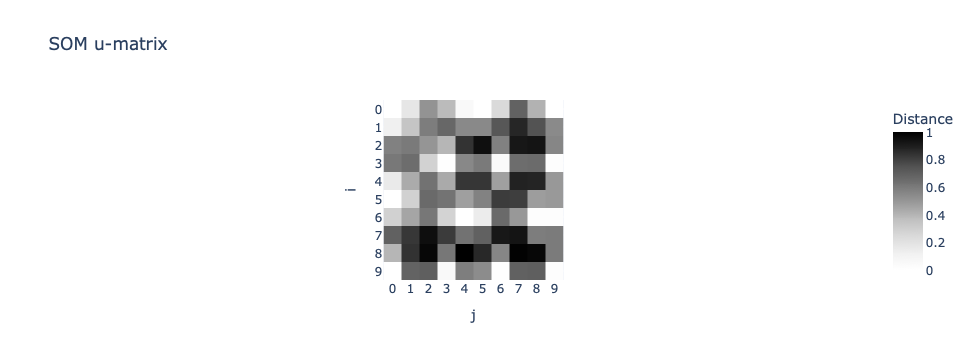

In [17]:
u_matrix_plot = kairo.plot_som_u_matrix(som)
u_matrix_plot.show()

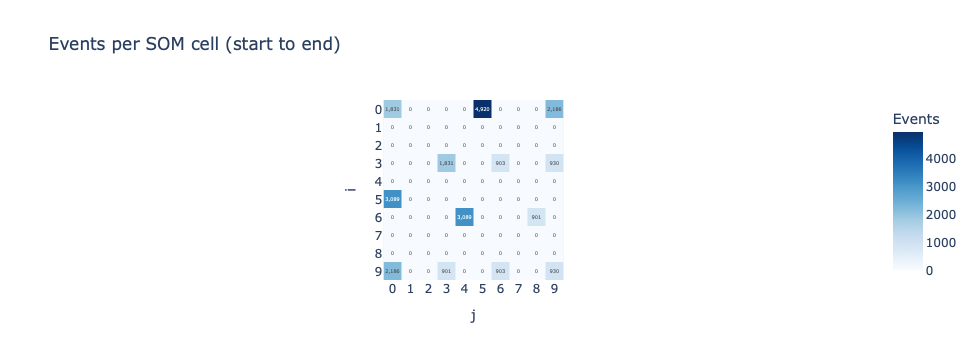

In [18]:
heatmap_plot = kairo.plot_som_heatmap(features_and_clusters, size=(10,10), 
                                 #start_date="2010-04-29", 
                                 #end_date="2018-05-29"
                                 )
heatmap_plot.show()

In [19]:
state_colors = kairo.get_som_state_colors(som)
#state_colors

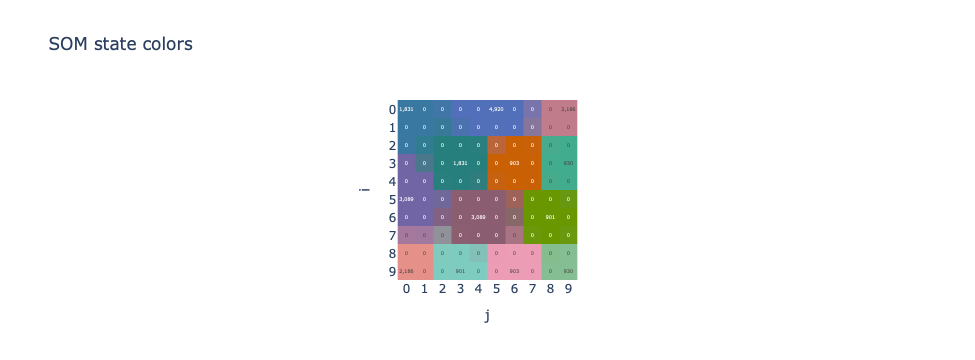

In [20]:
state_colors_plot = kairo.plot_som_state_colors(features_and_clusters, state_colors)
state_colors_plot.show()

In [21]:
case_trajectory = kairo.get_som_case_trajectory(features_and_clusters, case_id="case_000001")
case_trajectory

,state,start,end,duration,events
0,"(0, 5)",2020-01-01 00:17:34+00:00,2020-01-01 00:49:19+00:00,0 days 00:31:45,1
1,"(5, 0)",2020-01-01 00:49:19+00:00,2020-01-01 01:40:48+00:00,0 days 00:51:29,1
2,"(6, 4)",2020-01-01 01:40:48+00:00,2020-01-01 02:16:29+00:00,0 days 00:35:41,1
3,"(0, 9)",2020-01-01 02:16:29+00:00,2020-01-01 02:57:12+00:00,0 days 00:40:43,1
4,"(9, 0)",2020-01-01 02:57:12+00:00,2020-01-01 02:57:12+00:00,0 days 00:00:00,1


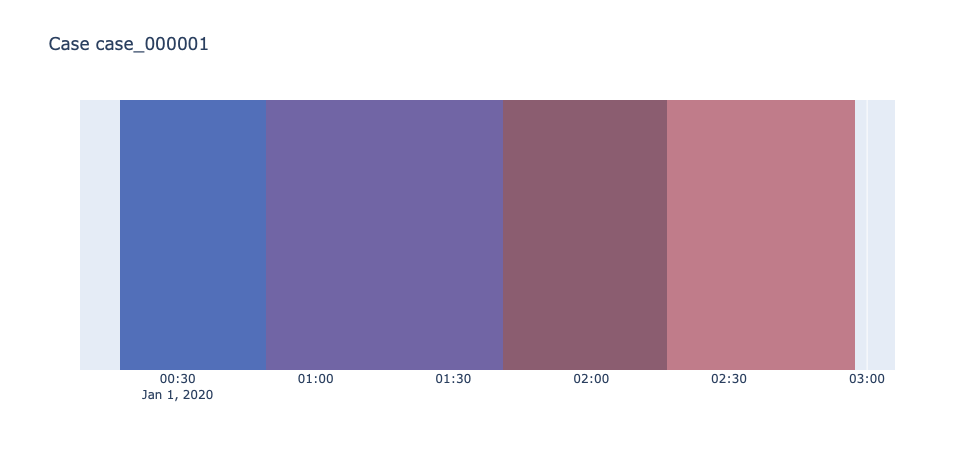

In [22]:
case_trajectory_plot = kairo.plot_som_case_trajectory(case_trajectory, state_colors, case_id="case_000001")
case_trajectory_plot

In [23]:
case_trajectories = kairo.get_som_case_trajectories(features_and_clusters, max_cases=20)
case_trajectories

,case,state,start,end,duration,events
0,case_000001,"(0, 5)",2020-01-01 00:17:34+00:00,2020-01-01 00:49:19+00:00,0 days 00:31:45,1
1,case_000001,"(5, 0)",2020-01-01 00:49:19+00:00,2020-01-01 01:40:48+00:00,0 days 00:51:29,1
2,case_000001,"(6, 4)",2020-01-01 01:40:48+00:00,2020-01-01 02:16:29+00:00,0 days 00:35:41,1
3,case_000001,"(0, 9)",2020-01-01 02:16:29+00:00,2020-01-01 02:57:12+00:00,0 days 00:40:43,1
4,case_000001,"(9, 0)",2020-01-01 02:57:12+00:00,2020-01-01 02:57:12+00:00,0 days 00:00:00,1
...,...,...,...,...,...,...
95,case_000020,"(0, 5)",2020-01-01 23:01:04+00:00,2020-01-01 23:36:19+00:00,0 days 00:35:15,1
96,case_000020,"(5, 0)",2020-01-01 23:36:19+00:00,2020-01-02 00:12:51+00:00,0 days 00:36:32,1
97,case_000020,"(6, 4)",2020-01-02 00:12:51+00:00,2020-01-02 00:48:53+00:00,0 days 00:36:02,1
98,case_000020,"(0, 9)",2020-01-02 00:48:53+00:00,2020-01-02 01:06:40+00:00,0 days 00:17:47,1


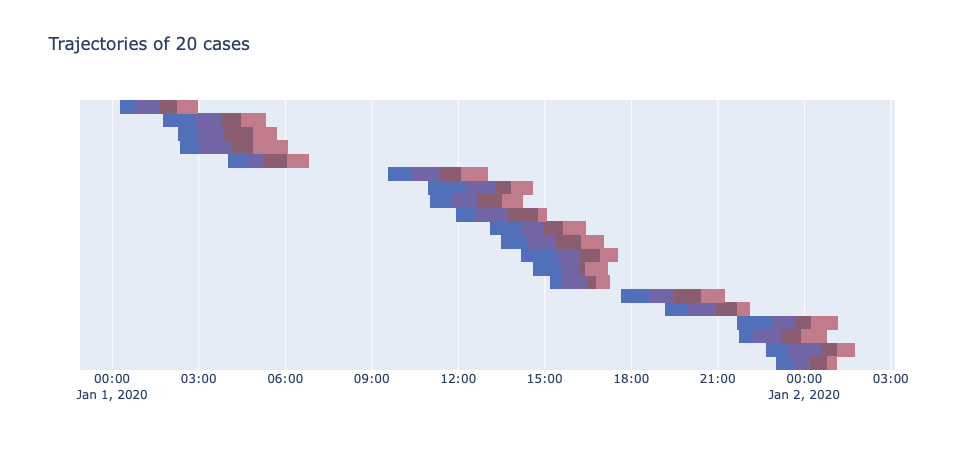

In [24]:
case_trajectories_plot = kairo.plot_som_case_trajectories(case_trajectories, state_colors)
case_trajectories_plot

In [25]:
freq_distributions = kairo.compute_state_distributions(features_and_clusters, signal_window="30D")
freq_distributions

state,"(0, 0)","(0, 5)","(0, 9)","(3, 3)","(3, 6)","(3, 9)","(5, 0)","(6, 4)","(6, 8)","(9, 0)","(9, 3)","(9, 6)","(9, 9)"
signal_window,,,,,,,,,,,,,
2019-12-10 00:00:00+00:00,0.000000,0.200680,0.198980,0.000000,0.000000,0.000000,0.200680,0.200680,0.000000,0.198980,0.000000,0.000000,0.000000
2020-01-09 00:00:00+00:00,0.000000,0.200664,0.199715,0.000000,0.000000,0.000000,0.200190,0.199715,0.000000,0.199715,0.000000,0.000000,0.000000
2020-02-08 00:00:00+00:00,0.000000,0.199501,0.200499,0.000000,0.000000,0.000000,0.200000,0.200000,0.000000,0.200000,0.000000,0.000000,0.000000
2020-03-09 00:00:00+00:00,0.024306,0.199901,0.166667,0.024306,0.008929,0.012401,0.175595,0.175595,0.011905,0.167163,0.011905,0.008929,0.012401
2020-04-08 00:00:00+00:00,0.099849,0.200202,0.054967,0.099849,0.045386,0.045386,0.099849,0.100353,0.054463,0.054967,0.053959,0.045386,0.045386
2020-05-08 00:00:00+00:00,0.101169,0.199797,0.047789,0.101169,0.050839,0.050330,0.099136,0.099136,0.050839,0.047789,0.051347,0.050330,0.050330
2020-06-07 00:00:00+00:00,0.100594,0.199817,0.049383,0.100594,0.050297,0.053041,0.099223,0.099223,0.047554,0.049383,0.047554,0.050754,0.052583
2020-07-07 00:00:00+00:00,0.093766,0.200412,0.055641,0.093766,0.050489,0.048429,0.106131,0.106131,0.045337,0.055641,0.045337,0.049974,0.048944
2020-08-06 00:00:00+00:00,0.101908,0.200301,0.051205,0.101908,0.046687,0.054217,0.097892,0.097892,0.047691,0.051205,0.047691,0.047189,0.054217


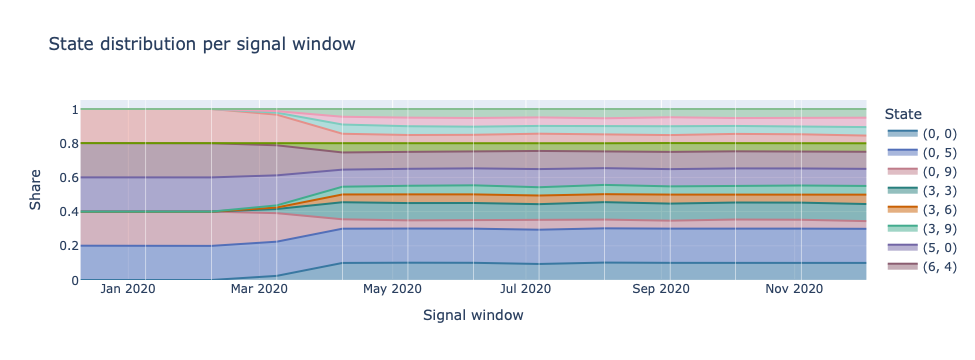

In [26]:
distributions_plot = kairo.plot_state_distributions(freq_distributions, state_colors)
distributions_plot.show()

In [27]:
drift_signal = kairo.compute_drift_signal(freq_distributions)
drift_signal

,signal_window,drift_score
0,2019-12-10 00:00:00+00:00,NaN
1,2020-01-09 00:00:00+00:00,0.000006
2,2020-02-08 00:00:00+00:00,0.000005
3,2020-03-09 00:00:00+00:00,1.799412
4,2020-04-08 00:00:00+00:00,0.477563
5,2020-05-08 00:00:00+00:00,0.002292
6,2020-06-07 00:00:00+00:00,0.000434
7,2020-07-07 00:00:00+00:00,0.002154
8,2020-08-06 00:00:00+00:00,0.002661
9,2020-09-05 00:00:00+00:00,0.002260


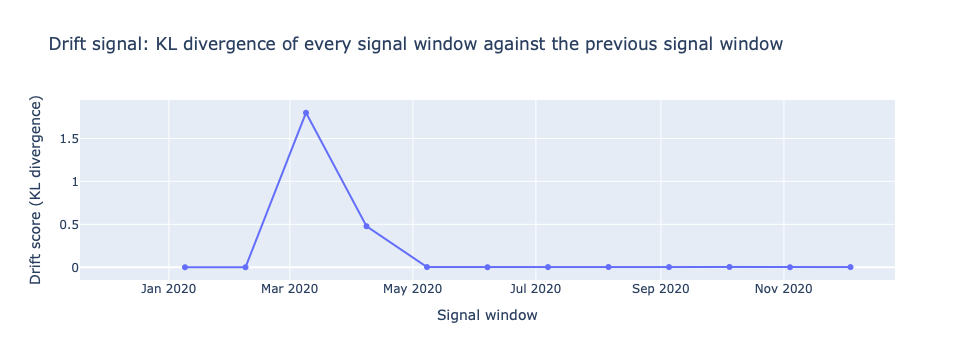

In [28]:
drift_signal_plot = kairo.plot_drift_signal(drift_signal)
drift_signal_plot.show()

In [29]:
abs_log_stats = kairo.abstract_log_stats(stats)
abs_log_stats

'Event log: 24,600 events of 4,920 cases, 5 activities and 4 resources, from 2020-01-01 00:17:34+00:00 to 2020-12-31 02:02:27+00:00.\nThroughput time per case in days: min 0.06, mean 0.13, median 0.13, max 0.20.\nEvents per case: min 5, mean 5.0, median 5.0, max 5.\nEvents per activity: a (4,920), b (4,920), c (4,920), d (4,920), e (4,920)\nMost active resources: res_02 (9,065), res_01 (7,166), res_03 (5,161), res_04 (3,208)'

In [30]:
abs_features = kairo.abstract_features(features)
abs_features

'Intra-case feature matrix: 24,600 rows, one per event, each describing its prefix, i.e., its case up to and including that event, with 56 feature columns.\nThe events belong to 4,920 cases and happened from 2020-01-01 00:17:34+00:00 to 2020-12-31 02:02:27+00:00.\nFeature groups:\n- act_freqs: One column per activity: how often the activity occurs in the prefix, divided by the number of events in the prefix. Here 5 columns, mean value 0.200, non-zero in 60.0% of the cells, highest column means act_freqs:a = 0.457, act_freqs:b = 0.219, act_freqs:c = 0.194\n- df_counts: One column per directly-follows pair a -> b that occurs in the log: how often b directly follows a in the prefix. Here 10 columns, mean value 0.200, non-zero in 20.0% of the cells, highest column means df_counts:a -> b = 0.502, df_counts:b -> c = 0.377, df_counts:a -> c = 0.298\n- act_set: One column per activity: 1 if the activity occurs in the prefix, else 0. Here 5 columns, mean value 0.600, non-zero in 60.0% of the ce

In [31]:
abs_pca = kairo.abstract_pca(pca, cut_component=13)
abs_pca

'PCA fitted 50 components on 56 feature columns. The cut keeps the first 13, which explain 100.0% of the variance.\nExplained variance per component: pc_1 31.1%, pc_2 14.3%, pc_3 13.0%, pc_4 9.8%, pc_5 8.1%, pc_6 5.5%, pc_7 4.9%, pc_8 4.5%, pc_9 4.0%, pc_10 3.2%, pc_11 1.6%, pc_12 0.0%, pc_13 0.0%, pc_14 0.0%, pc_15 0.0%, pc_16 0.0%, pc_17 0.0%, pc_18 0.0%, pc_19 0.0%, pc_20 0.0%, pc_21 0.0%, pc_22 0.0%, pc_23 0.0%, pc_24 0.0%, pc_25 0.0%, pc_26 0.0%, pc_27 0.0%, pc_28 0.0%, pc_29 0.0%, pc_30 0.0%, pc_31 0.0%, pc_32 0.0%, pc_33 0.0%, pc_34 0.0%, pc_35 0.0%, pc_36 0.0%, pc_37 0.0%, pc_38 0.0%, pc_39 0.0%, pc_40 0.0%, pc_41 0.0%, pc_42 0.0%, pc_43 0.0%, pc_44 0.0%, pc_45 0.0%, pc_46 0.0%, pc_47 0.0%, pc_48 0.0%, pc_49 0.0%, pc_50 0.0%\nFeatures with the strongest loadings on every kept component:\n- pc_1: act_set:d (+0.31), case_progress (+0.27), act_set:e (+0.26), act_set:c (+0.26)\n- pc_2: df_counts:a -> b (+0.40), df_counts:b -> c (+0.32), past_acts_2:a (+0.28), act_set:b (+0.24)\n- p

In [32]:
abs_states = kairo.abstract_states(state_freqs, state_distances, state_colors, clustering_scores=clustering_scores)
abs_states

'13 states occur among the 24,600 events. Events per state:\n- (0, 5): 4,920 events (20.0%)\n- (5, 0): 3,089 events (12.6%)\n- (6, 4): 3,089 events (12.6%)\n- (0, 9): 2,186 events (8.9%)\n- (9, 0): 2,186 events (8.9%)\n- (0, 0): 1,831 events (7.4%)\n- (3, 3): 1,831 events (7.4%)\n- (3, 9): 930 events (3.8%)\n- (9, 9): 930 events (3.8%)\n- (3, 6): 903 events (3.7%)\n- (9, 6): 903 events (3.7%)\n- (6, 8): 901 events (3.7%)\n- (9, 3): 901 events (3.7%)\nStates without events: (0, 1), (0, 2), (0, 3), (0, 4), (0, 6), (0, 7), (0, 8), (1, 0), (1, 1), (1, 2), (1, 3), (1, 4), (1, 5), (1, 6), (1, 7), (1, 8), (1, 9), (2, 0), (2, 1), (2, 2), (2, 3), (2, 4), (2, 5), (2, 6), (2, 7), (2, 8), (2, 9), (3, 0), (3, 1), (3, 2), (3, 4), (3, 5), (3, 7), (3, 8), (4, 0), (4, 1), (4, 2), (4, 3), (4, 4), (4, 5), (4, 6), (4, 7), (4, 8), (4, 9), (5, 1), (5, 2), (5, 3), (5, 4), (5, 5), (5, 6), (5, 7), (5, 8), (5, 9), (6, 0), (6, 1), (6, 2), (6, 3), (6, 5), (6, 6), (6, 7), (6, 9), (7, 0), (7, 1), (7, 2), (7, 3), (7

In [33]:
abs_case_trajectory = kairo.abstract_case_trajectory(case_trajectory, "case_000001")
abs_case_trajectory

'Trajectory of case case_000001, one line per visit of a state, in order:\n- (0, 5) from 2020-01-01 00:17:34+00:00 to 2020-01-01 00:49:19+00:00 (0 days 00:31:45, 1 events)\n- (5, 0) from 2020-01-01 00:49:19+00:00 to 2020-01-01 01:40:48+00:00 (0 days 00:51:29, 1 events)\n- (6, 4) from 2020-01-01 01:40:48+00:00 to 2020-01-01 02:16:29+00:00 (0 days 00:35:41, 1 events)\n- (0, 9) from 2020-01-01 02:16:29+00:00 to 2020-01-01 02:57:12+00:00 (0 days 00:40:43, 1 events)\n- (9, 0) from 2020-01-01 02:57:12+00:00 to 2020-01-01 02:57:12+00:00 (0 days 00:00:00, 1 events)'

In [34]:
abs_case_trajectories = kairo.abstract_case_trajectories(case_trajectories)
abs_case_trajectories

'Trajectories of 20 cases, from 2020-01-01 00:17:34+00:00 to 2020-01-02 01:43:39+00:00. A case visits 5.0 states on average and lasts 0 days 03:15:00 (median).\nThe most common paths through the states, with how many cases took them:\n- (0, 5) -> (5, 0) -> (6, 4) -> (0, 9) -> (9, 0): 20 cases (100.0%)\nThe most common moves from one state to the next:\n- (0, 5) -> (5, 0): 20 times\n- (5, 0) -> (6, 4): 20 times\n- (6, 4) -> (0, 9): 20 times\n- (0, 9) -> (9, 0): 20 times\nStates the cases start in: (0, 5) (20)\nStates the cases end in: (9, 0) (20)'

In [35]:
abs_distributions = kairo.abstract_state_distributions(freq_distributions)
abs_distributions

'State distribution over 13 signal windows from 2019-12-10 00:00:00+00:00 to 2020-12-04 00:00:00+00:00: the share of every state in each signal window.\nShare of every state over the signal windows, mean, lowest and highest:\n- (0, 0): mean 7.1%, lowest 0.0% in the signal window starting 2019-12-10 00:00:00+00:00, highest 10.2% in the signal window starting 2020-08-06 00:00:00+00:00\n- (0, 5): mean 20.0%, lowest 19.9% in the signal window starting 2020-12-04 00:00:00+00:00, highest 20.1% in the signal window starting 2019-12-10 00:00:00+00:00\n- (0, 9): mean 9.4%, lowest 4.5% in the signal window starting 2020-12-04 00:00:00+00:00, highest 20.0% in the signal window starting 2020-02-08 00:00:00+00:00\n- (3, 3): mean 7.1%, lowest 0.0% in the signal window starting 2019-12-10 00:00:00+00:00, highest 10.2% in the signal window starting 2020-08-06 00:00:00+00:00\n- (3, 6): mean 3.5%, lowest 0.0% in the signal window starting 2019-12-10 00:00:00+00:00, highest 5.5% in the signal window star

In [36]:
abs_drift_signal = kairo.abstract_drift_signal(drift_signal, divergence="kl", reference="recent")
abs_drift_signal

'Drift signal: for every signal window, the KL divergence between its state distribution and the mean of the 5 signal windows before it, the drift score of the signal window. 13 signal windows from 2019-12-10 00:00:00+00:00 to 2020-12-04 00:00:00+00:00.\nDrift scores: median 0.002, mean 0.191, highest 1.799.\nThe signal windows with the highest drift scores:\n- signal window starting 2020-03-09 00:00:00+00:00: 1.799\n- signal window starting 2020-04-08 00:00:00+00:00: 0.478\n- signal window starting 2020-10-05 00:00:00+00:00: 0.003\n- signal window starting 2020-08-06 00:00:00+00:00: 0.003\n- signal window starting 2020-05-08 00:00:00+00:00: 0.002'

In [46]:
llm = kairo.LLMConnector(
    provider="custom",
    #api_key=os.environ["ANTHROPIC_API_KEY"],
    model="qwen3-vl-8b-instruct",
    #model="Qwen/Qwen3-VL-32B-Instruct"
    
    #base_url="http://137.226.117.70:8000/v1"
    base_url="http://127.0.0.1:1234/v1"
)

In [47]:
chat_history = []
total_out_tokens = 0

In [48]:
# For initial request
messages = kairo.create_messages(provider="custom",
                                system_prompt=kairo.DEFAULT_SYSTEM_PROMPT, 
                                prompts=[abs_log_stats + abs_features + 
                                    abs_pca + abs_states + abs_case_trajectory + abs_case_trajectories
                                    + abs_distributions + abs_drift_signal + 
                                    "Very briefly analyze and summarize the given information. Do not use markdown format, just raw text"],
                                plots=[activity_plot, pca_plot_cut, u_matrix_plot, heatmap_plot,
                                           state_colors_plot, case_trajectory_plot, case_trajectories_plot,
                                           distributions_plot, drift_signal_plot])
chat_history += messages

num_tokens = kairo.count_input_tokens(provider="custom", messages=chat_history)
num_tokens

11798

In [43]:
# For follow up request
messages = kairo.create_messages(provider="custom",
                                system_prompt=None,
                                prompts=["what was my previous question very briefly"],
                                plots=[])
chat_history += messages

num_tokens = kairo.count_input_tokens(provider="custom", messages=chat_history)
num_tokens

12076

In [44]:
response = llm.call(messages=chat_history, max_tokens=64000)

answer = kairo.get_response_text(response)

chat_history.append({"role": "assistant", 
                     "content": answer})

print(answer)

You asked for a brief analysis and summary of the provided event log data using Kairo's state-based process monitoring framework.


In [50]:
# Alternative: Streaming

for piece in llm.stream(messages=messages, max_tokens=64000):
    print(piece, end="", flush=True)
    
response = llm.stream(messages=chat_history, max_tokens=64000)

answer = kairo.get_response_text(llm.response)

chat_history.append({"role": "assistant", 
                     "content": answer})

print(answer)

The process is highly consistent with a single, repeating pattern across all cases: every case starts in state (0, 5), moves to (5, 0), then to (6, 4), then to (0, 9), and finally ends in (9, 0). This path is followed by all 20 cases observed. The drift signal shows a single, sharp spike around March 2020, indicating a sudden change in the process mix — likely due to an external event or intervention — but this change was short-lived as the process quickly returned to its original pattern. The state distribution charts confirm that the same states dominate throughout the log, with only minor fluctuations. The PCA analysis shows that the data is well-reduced and captures all variance in just 18 components, suggesting a low-dimensional structure underlying the process behavior. The SOM visualization confirms this with clear clustering around the dominant path. Overall, the process exhibits very little drift over time, with one notable exception: March 2020.The process is highly consisten

In [42]:
out_tokens = kairo.count_output_tokens("custom", response)
total_out_tokens += out_tokens
total_out_tokens

229

In [ ]:
print(kairo.get_chat_history(chat_history))